#Multistage Countercurrent Liquid-Liquid Extraction Process

**References: Seader et al., 2016**

Liquid-liquid extraction, also known as solvent extraction, is a separation technique in which a liquid mixture containing several components is brought into contact with a solvent (Seader, 2016).

**Exercise 8.12:  Extraction of Acetone with Trichloroethane Using a Right-Triangular Diagram**

A continuous countercurrent extraction is carried out at 25°C, where a feed of 1000 kg/h containing 45 wt% acetone in water is treated with pure 1,1,2-trichloroethane. The goal is to produce a raffinate stream containing 10 wt% acetone.

Here is the equilibrium of data between acetone, water, and 1,1,2-trichloroethane.

- Extract Phase
<table border="1" style="padding:20px;">
  <tr>
    <th>Acetone</th>
    <th>Water</th>
    <th>Trichloroethane</th>
  </tr>
  <tr>
    <th>0.600</th>
    <th>0.130</th>
    <th>0.270</th>
  </tr>
  <tr>
    <th>0.500</th>
    <th>0.040</th>
    <th>0.460</th>
  </tr>
  <tr>
    <th>0.400</th>
    <th>0.030</th>
    <th>0.570</th>
  </tr>
  <tr>
    <th>0.300</th>
    <th>0.020</th>
    <th>0.680</th>
  </tr>
  <tr>
    <th>0.200</th>
    <th>0.015</th>
    <th>0.785</th>
  </tr>
  <tr>
    <th>0.100</th>
    <th>0.010</th>
    <th>0.890</th>
  </tr>
</table>

- Raffinate Phase
<table border="1" style="padding:20px;">
  <tr>
    <th>Acetone</th>
    <th>Water</th>
    <th>Trichloroethane</th>
  </tr>
  <tr>
    <th>0.550</th>
    <th>0.350</th>
    <th>0.100</th>
  </tr>
  <tr>
    <th>0.500</th>
    <th>0.430</th>
    <th>0.070</th>
  </tr>
  <tr>
    <th>0.400</th>
    <th>0.570</th>
    <th>0.030</th>
  </tr>
  <tr>
    <th>0.300</th>
    <th>0.680</th>
    <th>0.020</th>
  </tr>
  <tr>
    <th>0.200</th>
    <th>0.790</th>
    <th>0.010</th>
  </tr>
  <tr>
    <th>0.100</th>
    <th>0.895</th>
    <th>0.005</th>
  </tr>
</table>

- Tie Line
<table>
  <tr>
    <th>Raffinate, Weight Fraction Acetone </th>
    <th>Extract Weight Fraction Acetone </th>
  </tr>
   <tr>
    <th>0.44 </th>
    <th>0.56 </th>
  </tr>
  <tr>
    <th>0.29 </th>
    <th>0.40 </th>
  </tr>
  <tr>
    <th>0.12 </th>
    <th>0.18 </th>
  </tr>
</table>

Task:
- Determine the minimum solvent flow rate.
- Calculate the number of stages needed when the solvent rate is set to 1.5 times the minimum.
- Identify the flow rate and composition of each stream exiting every stage.

<strong>Disclaimer:</strong> The content presented in this file is provided for learning purposes only.

#Step 1: Fitting the Data through Extrapolation on the Equilibrium Data

Objective:
- Apply linear regression to fit the tie line data.
- Perform extrapolation to model the equilibrium data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.optimize import fsolve


#Extract Phase
extract_phase_acetone = np.array([0.1,0.2,0.3,0.4,0.5,0.6])
extract_phase_trichloroethane = np.array([0.89, 0.785, 0.68, 0.57, 0.46, 0.27])

#Raffinate Phase
raffinate_phase_acetone = np.array([0.1,0.2,0.3,0.4,0.5,0.55])
raffinate_phase_trichloroethane = np.array([0.005,0.01,0.02,0.03,0.07,0.10])

#Tie Line Data
tie_line_acetone_raffinate = np.array([0.12, 0.29, 0.44])
tie_line_acetone_extract = np.array([0.18, 0.40, 0.56])

#Extrapolate Extract Phase
f_extract = interp1d(extract_phase_acetone, extract_phase_trichloroethane,fill_value="extrapolate",kind='quadratic')
f_raffinate = interp1d(raffinate_phase_acetone,raffinate_phase_trichloroethane,fill_value="extrapolate",kind='quadratic')


#Inversion Extract Phase
f_extract_inversion = interp1d(extract_phase_trichloroethane,extract_phase_acetone,kind='quadratic')
#Extrapolate Tie Line Point
extract_phase_trichloroethane_extrapolate = f_extract(tie_line_acetone_extract)
raffinate_phase_trichloroethane_extrapolate = f_raffinate(tie_line_acetone_raffinate)

#Step 2: Plotting Using a Right Triangle
Objective:

- To plot the equilibrium data and construct the tie line using a right triangle approach.

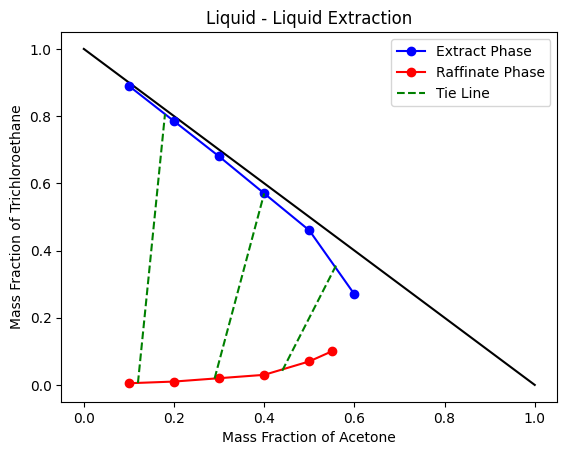

In [2]:
#Calculating Diluent Fraction
def diluent_fraction_calc (frac_1,frac_2):
  y = 1 - (frac_1 + frac_2)
  return y

#Plotting Right Triangle Line
def right_triangle_line (x):
  y = -x + 1
  return y

x = np.linspace(0,1,1000)
y = right_triangle_line(x)

#Plot the Graph
plt.plot(x,y,color="black")
plt.plot(extract_phase_acetone,extract_phase_trichloroethane,label="Extract Phase",color="blue",marker='o') #Plot the Extract Phase
plt.plot(raffinate_phase_acetone  ,raffinate_phase_trichloroethane,label="Raffinate Phase",color="red",marker='o') #Plot the Raffinate Phase

#Plot the Tie Line
for i in range(len(tie_line_acetone_extract)):
  if i == 0:
    plt.plot([tie_line_acetone_raffinate[i], tie_line_acetone_extract[i]],[raffinate_phase_trichloroethane_extrapolate[i],extract_phase_trichloroethane_extrapolate[i]],label="Tie Line",color="green",linestyle='--')
  else:
    plt.plot([tie_line_acetone_raffinate[i], tie_line_acetone_extract[i]],[raffinate_phase_trichloroethane_extrapolate[i],extract_phase_trichloroethane_extrapolate[i]],color="green",linestyle='--')
plt.title("Liquid - Liquid Extraction")
plt.xlabel("Mass Fraction of Acetone")
plt.ylabel("Mass Fraction of Trichloroethane")
plt.legend()
plt.show()


#Step 3 : Fitting the Tie Line Data

Tie line data fitting is carried out using the Othmer-Tobias approach. The equation is as follows (Othmer & Tobias, 1942):

$\ln(\frac {1-w_{solvent,e}}{w_{solvent,e}})=A + B\, \ln (\frac{1-w_{diluent,r}}{w_{diluent,r}})$

Where:
- A = Intercept
- B = Slope
- $w_{diluent,e}$ = Mass Fraction of Diluent in Raffinate Phase
- $w_{solvent,e}$ = Mass Fraction of Solvent in Extract Phase


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

#Convert the Data in Tie Line

def othmer_tobias_value(fraction):
  y = (1-fraction)/(fraction)
  y = np.log(y)
  return y

def inverse_othmer_tobias(values):
  return 1/(1+ np.exp(values))

#Develop the function of linear line
def linear_line (x,x1,y1,x2,y2):
  return (y2-y1)/(x2-x1)*(x-x1)+y1

#Develop the function of gradient
def gradient (x1,y1,x2,y2):
  return (y2-y1)/(x2-x1)

#Develop a function to calculate the diluent fraction.
def diluent_fraction(x1,x2):
  return 1-(x1+x2)

#Determine x and y values
x_othmer_tobias_data = othmer_tobias_value(diluent_fraction(tie_line_acetone_raffinate,raffinate_phase_trichloroethane_extrapolate))
y_othmer_tobias_data = othmer_tobias_value(extract_phase_trichloroethane_extrapolate)

#Fit the data through Linear Regression
linear_fit_model = LinearRegression()
linear_fit_model.fit(x_othmer_tobias_data.reshape(-1, 1), y_othmer_tobias_data.reshape(-1, 1))

#Fit the data through Linear Regression fof inversion
inversion_linear_fit_model = LinearRegression()
inversion_linear_fit_model.fit(y_othmer_tobias_data.reshape(-1, 1),x_othmer_tobias_data.reshape(-1, 1))

print("R2 Score :",r2_score(y_othmer_tobias_data,linear_fit_model.predict(x_othmer_tobias_data.reshape(-1, 1))))

R2 Score : 0.9978637658213897


#Step 3: Determining the minimum rate of solvent

Objective:
- Find the extract output at the minimum solvent flow rate.

Operating Condition:
- $z_{feed,acetone} = 0.45$
- $F = 1,000\, kg/hr$

Material Balance of Extraction Process:
- Overall Material Balance:
  
    $F + S = E + R$
  
- Material Balance:

    $x_{F,1}F + x_{S,1}S = x_{E,1}E + x_{R,1}R$

- Mixing Material Balance:

    $F + S = M$

- Acetone Mixing Material Balance:

    $x_{F,1}F + x_{S,1}S = x_{M,1}M$
      
Explanation:

The minimum solvent rate occurs when the feed lies on an extended tie line, meaning the process would require infinite stages.

In [4]:
def mixing_material_balance (feed_flow, solvent_flow):
  mixing_flow = feed_flow + solvent_flow
  return mixing_flow

def fraction_mixing (feed_fraction, solvent_fraction,feed_flow,solvent_flow):
  fraction_mixing = (feed_fraction*feed_flow + solvent_fraction*solvent_flow)/mixing_material_balance(feed_flow,solvent_flow)
  return fraction_mixing

#Feed Point
feed_input = np.array([0.45,0])

#Raffinate Point
raffinate_outlet_acetone = 0.1
raffinate_solvent_outlet = f_raffinate(raffinate_outlet_acetone)
raffinate_outlet = np.array([raffinate_outlet_acetone,raffinate_solvent_outlet])

#Solvent Point
solvent_fraction = np.array([0,1])

#Feed Flow
feed_flow = 1000
guess_solvent_flow = 200

def finding_minimum_solvent_flow_rate(solvent_flow):
    #Calculate Mixing Fraction
    x_acetone_mixing_fraction = fraction_mixing(feed_input[0],solvent_fraction[0],feed_flow,solvent_flow)
    x_solvent_mixing_fraction = fraction_mixing(feed_input[1],solvent_fraction[1],feed_flow,solvent_flow)

    #Determining Extract Point
    def finding_extract_point(x):
      y_raffinate_mixing_line = linear_line(x,raffinate_outlet[0],raffinate_outlet[1],x_acetone_mixing_fraction,x_solvent_mixing_fraction)
      y_extract_line = f_extract(x)
      return y_raffinate_mixing_line - y_extract_line

    guess_x = 0.5
    extract_point = fsolve(finding_extract_point,guess_x)

    #Determining Raffinate Point based on Tie Line
    water_raffinate_point = inverse_othmer_tobias(inversion_linear_fit_model.predict(othmer_tobias_value(f_extract(extract_point)).reshape(-1, 1)))

    def finding_acetone_fraction (x):
      fraction_free_water = 1 - water_raffinate_point[0][0]
      fraction_acetone_trichloroethane_raffinate = x + f_raffinate(x)
      return fraction_free_water - fraction_acetone_trichloroethane_raffinate

    acetone_raffinate_fraction = fsolve(finding_acetone_fraction,water_raffinate_point[0][0])

    gradient_tie_line = gradient(acetone_raffinate_fraction,f_raffinate(acetone_raffinate_fraction),extract_point,f_extract(extract_point))
    gradient_feed_extract = gradient(feed_input[0],feed_input[1],extract_point,f_extract(extract_point))
    return gradient_tie_line - gradient_feed_extract


#Determining Minimum Solvent Flow
minimum_solvent_flow = fsolve(finding_minimum_solvent_flow_rate,guess_solvent_flow)

#Calculating Solvent per Feed Ratio
def solvent_per_feed (solvent_rate,feed_rate):
  return solvent_rate/feed_rate

minimum_solvent_per_feed = solvent_per_feed(minimum_solvent_flow,feed_flow)

#Display the result
print(f"The minimum solvent rate is {minimum_solvent_flow[0]:.2f} kg/hr")
print(f"The solvent per feed ratio is {minimum_solvent_per_feed[0]:.2f}")

The minimum solvent rate is 221.74 kg/hr
The solvent per feed ratio is 0.22


#Step 4 : Calculating the operating solvent flow rate and extract point at minimum and operating solvent rate

In this case, the operating solvent flow rate can be determined using the following equation:

<div align ="center">
$S_{process}=1.5 * S_{minimum}$
</div>


In [5]:
def determining_operating_solvent_flow_rate(multiplier,min_solvent_rate):
  return multiplier * min_solvent_rate

def extract_raffinate_line_minimum (x):
  x_acetone_mixing_fraction_minimum = fraction_mixing(feed_input[0],solvent_fraction[0],feed_flow,minimum_solvent_flow)
  x_solvent_mixing_fraction_minimum = fraction_mixing(feed_input[1],solvent_fraction[1],feed_flow,minimum_solvent_flow)
  y_raffinate_mixing_line = linear_line(x,raffinate_outlet[0],raffinate_outlet[1],x_acetone_mixing_fraction_minimum,x_solvent_mixing_fraction_minimum)
  y_extract_line = f_extract(x)
  return y_raffinate_mixing_line - y_extract_line

def extract_raffinate_line_operating (x):
  x_acetone_mixing_fraction_operating = fraction_mixing(feed_input[0],solvent_fraction[0],feed_flow,operating_solvent_rate)
  x_solvent_mixing_fraction_operating = fraction_mixing(feed_input[1],solvent_fraction[1],feed_flow,operating_solvent_rate)
  y_raffinate_mixing_line = linear_line(x,raffinate_outlet[0],raffinate_outlet[1],x_acetone_mixing_fraction_operating,x_solvent_mixing_fraction_operating)
  y_extract_line = f_extract(x)
  return y_raffinate_mixing_line - y_extract_line

#Determining the operating solvent flow rate
number_multiplier = 1.5
operating_solvent_rate = np.round(determining_operating_solvent_flow_rate(number_multiplier,minimum_solvent_flow),2)

#Determining the extract output at minimum solvent rate
x_guess = 0.5
acetone_extract_phase_result = fsolve(extract_raffinate_line_minimum,x_guess)
trichloroethane_extract_phase_result = f_extract(acetone_extract_phase_result)

#Determining the raffinate output at minimum solvent rate
water_raffinate_point = inverse_othmer_tobias(inversion_linear_fit_model.predict(othmer_tobias_value(f_extract(acetone_extract_phase_result)).reshape(-1, 1)))
def determine_acetone_fraction (x):
  fraction_free_water = 1 - water_raffinate_point[0][0]
  fraction_acetone_trichloroethane_raffinate = x + f_raffinate(x)
  return fraction_free_water - fraction_acetone_trichloroethane_raffinate
acetone_raffinate_fraction_minimum_flow = fsolve(determine_acetone_fraction,water_raffinate_point[0][0])
trichloroethane_raffinate_fraction_minimum_flow = f_raffinate(acetone_raffinate_fraction_minimum_flow)


#Determining the extract output at operating solvent rate
x_guess = 0.5
acetone_extract_phase_result_operating = fsolve(extract_raffinate_line_operating,x_guess)
trichloroethane_extract_phase_result_operating = f_extract(acetone_extract_phase_result_operating)

#Display the result
print(f"Fraction of acetone at the minimum solvent rate is {acetone_extract_phase_result[0]:.2f}")
print(f"Fraction of trichloroethane at the minimum solvent rate is {trichloroethane_extract_phase_result[0]:.2f}")
print(f"Fraction of acetone at the operating solvent rate is {acetone_extract_phase_result_operating [0]:.2f}")
print(f"Fraction of trichloroethane at the operating solvent rate is {trichloroethane_extract_phase_result_operating[0]:.2f}")
print(f"The solvent rate of extraction process is {operating_solvent_rate[0]:.2f} kg/hr")

Fraction of acetone at the minimum solvent rate is 0.58
Fraction of trichloroethane at the minimum solvent rate is 0.32
Fraction of acetone at the operating solvent rate is 0.52
Fraction of trichloroethane at the operating solvent rate is 0.43
The solvent rate of extraction process is 332.62 kg/hr


#Step 5: Calculating the extract output based on the operating solvent flow rate.

Objective:
- Find the extract output at the operating solvent flow rate.
- Visualizing the right triangle to compare extract output at the minimum solvent flow rate and the operating solvent flow rate.


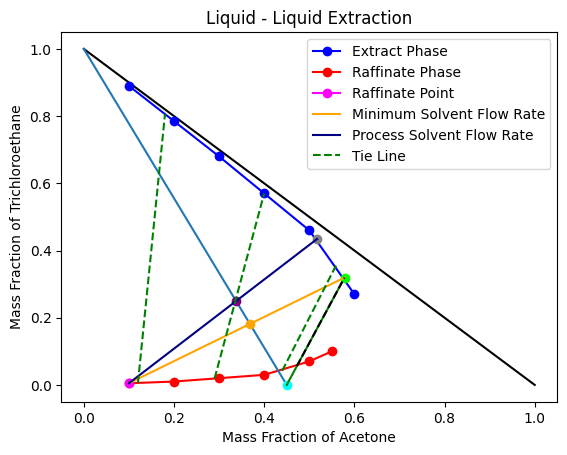

In [6]:
#Calculating the mixing point at the minimum solvent flow rate
acetone_minimum_solvent = fraction_mixing(feed_input[0],solvent_fraction[0],feed_flow,minimum_solvent_flow)
trichloroethane_minimum_solvent = fraction_mixing(feed_input[1],solvent_fraction[1],feed_flow,minimum_solvent_flow)

#Calculating the mixing point at the operating solvent flow rate
acetone_operating_solvent = fraction_mixing(feed_input[0],solvent_fraction[0],feed_flow,operating_solvent_rate)
trichloroethane_operating_solvent = fraction_mixing(feed_input[1],solvent_fraction[1],feed_flow,operating_solvent_rate)

#Plot the Graph
plt.plot(x,y,color="black")
plt.plot(extract_phase_acetone,extract_phase_trichloroethane,label="Extract Phase",color="blue",marker='o') #Plot the Extract Phase
plt.plot(raffinate_phase_acetone  ,raffinate_phase_trichloroethane,label="Raffinate Phase",color="red",marker='o') #Plot the Raffinate Phase

#Plot the Feed-Solvent Line
plt.plot([feed_input[0],solvent_fraction[0]],[feed_input[1],solvent_fraction[1]])

#Plot the Feed Point
plt.plot(feed_input[0],feed_input[1],marker='o',color='cyan')

#Plot the Raffinate Point
plt.plot(raffinate_outlet[0],raffinate_outlet[1],marker='o',color='magenta',label = "Raffinate Point")

#Plot the Feed-Extract Line at the Minimum Solvent Flow Rate
plt.plot([feed_input[0],acetone_extract_phase_result[0]],[feed_input[1],trichloroethane_extract_phase_result[0]],color='green')

#Plot the Mixing Point at the Minimum Solvent Flow Rate
plt.plot(acetone_minimum_solvent,trichloroethane_minimum_solvent,marker='o',color='orange')

#Plot the Mixing Point at the Operating Solvent Flow Rate
plt.plot(acetone_operating_solvent,trichloroethane_operating_solvent,marker='o',color='purple')

#Plot the Extract Point at the Minimum Solvent Flow Rate
plt.plot(acetone_extract_phase_result,trichloroethane_extract_phase_result[0],marker='o',color='lime')

#Plot the Extract Point at the Operating Solvent Flow Rate
plt.plot(acetone_extract_phase_result_operating[0],trichloroethane_extract_phase_result_operating[0],marker='o',color='gray')

#Plot Extract-Raffinate at the Minimum Solvent Flow Rate
plt.plot([raffinate_outlet[0],acetone_extract_phase_result[0]],[raffinate_outlet[1],trichloroethane_extract_phase_result[0]],color="orange",label="Minimum Solvent Flow Rate")

#Plot Extract-Raffinate at the Operating Solvent Flow Rate
plt.plot([raffinate_outlet[0],acetone_extract_phase_result_operating[0]],[raffinate_outlet[1],trichloroethane_extract_phase_result_operating[0]],color="navy",label="Process Solvent Flow Rate")

#Plot the Tie Line at the Minimum Solvent Flow Rate
plt.plot([acetone_raffinate_fraction_minimum_flow,acetone_extract_phase_result],[trichloroethane_raffinate_fraction_minimum_flow,trichloroethane_extract_phase_result],linestyle='--',color='black')

#Plot the Tie Line
for i in range(len(tie_line_acetone_extract)):
  if i == 0:
    plt.plot([tie_line_acetone_raffinate[i], tie_line_acetone_extract[i]],[raffinate_phase_trichloroethane_extrapolate[i],extract_phase_trichloroethane_extrapolate[i]],label="Tie Line",color="green",linestyle='--')
  else:
    plt.plot([tie_line_acetone_raffinate[i], tie_line_acetone_extract[i]],[raffinate_phase_trichloroethane_extrapolate[i],extract_phase_trichloroethane_extrapolate[i]],color="green",linestyle='--')
plt.title("Liquid - Liquid Extraction")
plt.xlabel("Mass Fraction of Acetone")
plt.ylabel("Mass Fraction of Trichloroethane")
plt.legend()
plt.show()


#Step 6: Constructing Operating Line of Liquid-liquid Extraction Process

Task:
- Operating line point ($P$) is determined from the intersection of the Operating Feed-Extract line and the Raffinate-Solvent line.

Note:
- If the calculated acetone fraction in the raffinate stream of the final stage falls below the expected outlet fraction, it is fixed at the target value of 0.1 as a mitigation measure to prevent negative mass flow in one of the extraction stages.

In [7]:
#Determining Operating Line Point (P)
def determining_p_point(x):
  y_raffinate_solvent_line = linear_line(x,raffinate_outlet[0],raffinate_outlet[1],solvent_fraction[0],solvent_fraction[1])
  y_extract_feed_line = linear_line(x,feed_input[0],feed_input[1],acetone_extract_phase_result_operating[0],trichloroethane_extract_phase_result_operating[0])
  return y_raffinate_solvent_line - y_extract_feed_line

x_p_guess = 1
x_p_point = fsolve(determining_p_point,x_p_guess)
y_p_point = linear_line(x_p_point,feed_input[0],feed_input[1],acetone_extract_phase_result_operating[0],trichloroethane_extract_phase_result_operating[0])

print(f"P point on this process is ({x_p_point[0]:.2f}, {y_p_point[0]:.2f})")

#Developing the Operating Line of Liquid-liquid Extraction Process
extract_point_operating = np.array([acetone_extract_phase_result_operating[0]])
raffinate_tie_line_operating = np.array([])
raffinate_operating_line = np.array([feed_input[0]])

while raffinate_operating_line[-1] >= raffinate_outlet_acetone:
  extract_output_trichloroethane = f_extract(extract_point_operating[-1])
  extract_othmer_tobias_value = othmer_tobias_value(extract_output_trichloroethane)
  raffinate_output_water = inverse_othmer_tobias(inversion_linear_fit_model.predict(extract_othmer_tobias_value.reshape(-1, 1)))
  def determine_acetone_fraction (x):
      fraction_free_water = 1 - raffinate_output_water[0][0]
      fraction_acetone_trichloroethane_raffinate = x + f_raffinate(x)
      return fraction_free_water - fraction_acetone_trichloroethane_raffinate
  new_var = raffinate_output_water[0][0]
  raffinate_output_acetone = fsolve(determine_acetone_fraction, new_var)
  raffinate_tie_line_operating = np.append(raffinate_tie_line_operating,raffinate_output_acetone)
  if raffinate_tie_line_operating[-1] < raffinate_outlet_acetone:
    raffinate_tie_line_operating[-1] = np.round(raffinate_tie_line_operating[-1],1)
    break
  else:
#Find Extract Point
    def determine_extract_point(x):
      p_raffinate_line = linear_line(x,x_p_point,y_p_point,raffinate_tie_line_operating[-1],f_raffinate(raffinate_tie_line_operating[-1]))
      return p_raffinate_line - f_extract(x)

#Determine Extract Point
  extract_point_acetone = fsolve(determine_extract_point,0)
  extract_point_operating = np.append(extract_point_operating,extract_point_acetone)
  raffinate_operating_line = np.append(raffinate_operating_line,raffinate_output_acetone)

data_extract_point_operating = np.round(extract_point_operating,3)
data_raffinate_tie_line_operating = np.round(raffinate_tie_line_operating,3)
data_raffinate_operating_line = np.round(raffinate_operating_line,3)

#Determining number of stages
number_of_stages = len(raffinate_operating_line)
#Display the extract point on the kondisi operasi
print("The number of stages on this process is",number_of_stages)
print("The extract point during the extraction process: ",data_extract_point_operating)
print("The raffinate point during the extraction process: ",data_raffinate_tie_line_operating)
print("The operating line of the extraction process: ",data_raffinate_operating_line)

P point on this process is (0.24, -1.37)
The number of stages on this process is 5
The extract point during the extraction process:  [0.517 0.441 0.343 0.236 0.111]
The raffinate point during the extraction process:  [0.387 0.311 0.237 0.16  0.1  ]
The operating line of the extraction process:  [0.45  0.387 0.311 0.237 0.16 ]


#Step 7: Plotting the Right Triangle for the Extraction Process at the Operating Solvent Flow Rate

Task:

- Display the right triangle on the extraction process diagram using the operating solvent flow rate.

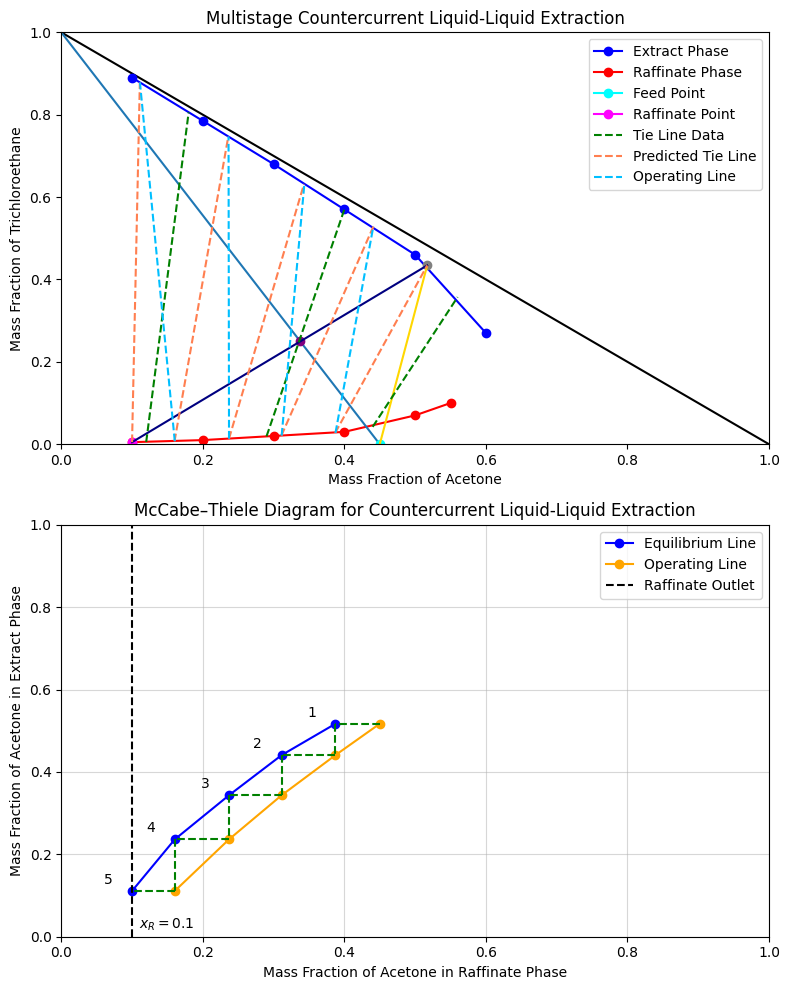

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(8, 10))

#Plot the Graph

#Subplot 1
ax[0].plot(x,y,color="black")
ax[0].plot(extract_phase_acetone,extract_phase_trichloroethane,label="Extract Phase",color="blue",marker='o') #Plot the Extract Phase
ax[0].plot(raffinate_phase_acetone  ,raffinate_phase_trichloroethane,label="Raffinate Phase",color="red",marker='o') #Plot the Raffinate Phase

#Plot the Feed-Solvent Line
ax[0].plot([feed_input[0],solvent_fraction[0]],[feed_input[1],solvent_fraction[1]])

#Plot the Feed Point
ax[0].plot(feed_input[0],feed_input[1],marker='o',color='cyan',label="Feed Point")

#Plot the Raffinate Point
ax[0].plot(raffinate_outlet[0],raffinate_outlet[1],marker='o',color='magenta',label = "Raffinate Point")

#Plot the Mixing Point at the Operating Solvent Flow Rate
ax[0].plot(acetone_operating_solvent,trichloroethane_operating_solvent,marker='o',color='purple')

#Plot the Extract Point at the Operating Solvent Flow Rate
ax[0].plot(acetone_extract_phase_result_operating[0],trichloroethane_extract_phase_result_operating[0],marker='o',color='gray')

#Plot Extract-Raffinate at the Operating Solvent Flow Rate
ax[0].plot([feed_input[0],acetone_extract_phase_result_operating[0]],[feed_input[1],trichloroethane_extract_phase_result_operating[0]],color="gold")

#Plot Extract-Raffinate at the Operating Solvent Flow Rate
ax[0].plot([raffinate_outlet[0],acetone_extract_phase_result_operating[0]],[raffinate_outlet[1],trichloroethane_extract_phase_result_operating[0]],color="navy")

#Plot the Tie Line
for i in range(len(tie_line_acetone_extract)):
  if i == 0:
    ax[0].plot([tie_line_acetone_raffinate[i], tie_line_acetone_extract[i]],[raffinate_phase_trichloroethane_extrapolate[i],extract_phase_trichloroethane_extrapolate[i]],label="Tie Line Data",color="green",linestyle='--')
  else:
    ax[0].plot([tie_line_acetone_raffinate[i], tie_line_acetone_extract[i]],[raffinate_phase_trichloroethane_extrapolate[i],extract_phase_trichloroethane_extrapolate[i]],color="green",linestyle='--')

#Plotting the Tie Line under Operating Conditions
for i in range(len(raffinate_tie_line_operating)):
  if i == 0:
    ax[0].plot([data_raffinate_tie_line_operating[i], data_extract_point_operating[i]],[f_raffinate(raffinate_tie_line_operating[i]),f_extract(extract_point_operating[i])],color="coral",linestyle='--',label="Predicted Tie Line")
  else:
    ax[0].plot([data_raffinate_tie_line_operating[i], data_extract_point_operating[i]],[f_raffinate(raffinate_tie_line_operating[i]),f_extract(extract_point_operating[i])],color="coral",linestyle='--')

#Plotting the Operating Line
for i in range(len(raffinate_tie_line_operating)):
  if i == 0:
    continue
  if i == 1:
    ax[0].plot([raffinate_operating_line[i], extract_point_operating[i]],[f_raffinate(raffinate_operating_line[i]),f_extract(extract_point_operating[i])],color="deepskyblue",linestyle='--',label="Operating Line")
  else:
    ax[0].plot([raffinate_operating_line[i], extract_point_operating[i]],[f_raffinate(raffinate_operating_line[i]),f_extract(extract_point_operating[i])],color="deepskyblue",linestyle='--')


#Display the Diagram
ax[0].set_title("Multistage Countercurrent Liquid-Liquid Extraction")
ax[0].set_xlim(0,1)
ax[0].set_ylim(0,1)
ax[0].set_xlabel("Mass Fraction of Acetone")
ax[0].set_ylabel("Mass Fraction of Trichloroethane")
ax[0].legend()

ax[1].plot(raffinate_tie_line_operating,extract_point_operating,label="Equilibrium Line",marker='o',color="blue")
ax[1].plot(raffinate_operating_line,extract_point_operating,label="Operating Line",marker='o',color="orange")
#Plotting the Stage
for i in range(len(raffinate_tie_line_operating)):
  #Horinzontal Line
  ax[1].plot([raffinate_operating_line[i],raffinate_tie_line_operating[i]],[extract_point_operating[i],extract_point_operating[i]],color="green",linestyle='--')
  ax[1].annotate(i+1,xy=(raffinate_tie_line_operating[i]-0.05,extract_point_operating[i]),textcoords="offset points",xytext=(5, 5))
  #Vertical Line
  if i < len(raffinate_tie_line_operating) - 1:
    ax[1].plot([raffinate_tie_line_operating[i],raffinate_tie_line_operating[i]],[extract_point_operating[i],extract_point_operating[i+1]],color="green",linestyle='--')

ax[1].grid(True,alpha=0.5)
ax[1].set_xlim(0,1)
ax[1].set_ylim(0,1)
ax[1].axvline(x=0.1,color="black",linestyle='--',label="Raffinate Outlet")
ax[1].text(raffinate_outlet_acetone+0.01,raffinate_outlet_acetone-0.08,f"$x_R={raffinate_outlet_acetone}$",fontsize=10)
ax[1].set_title("McCabe–Thiele Diagram for Countercurrent Liquid-Liquid Extraction")
ax[1].set_xlabel("Mass Fraction of Acetone in Raffinate Phase")
ax[1].set_ylabel("Mass Fraction of Acetone in Extract Phase")
ax[1].legend()
plt.tight_layout()
plt.show()

#Step 8 : Plotting Acetone Fractions in the Raffinate and Extract Phases at Each Stage

Task:
- Visualizing acetone fractions in the raffinate and extract phases throughout the stages

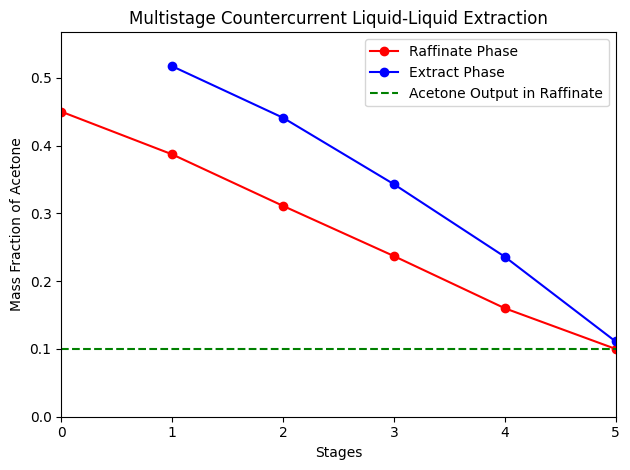

In [9]:
#Plotting the acetone fraction in raffinate and extract phase at each stages

#Data Preparation
acetone_raffinate_output_process = np.append(data_raffinate_operating_line,raffinate_tie_line_operating[-1])
acetone_extract_output_process = data_extract_point_operating
stages_raffinate = list(range(len(acetone_raffinate_output_process)))
stages_extract = list(range(1,len(extract_point_operating)+1))

#Plotting the Mass Fraction of Acetone
plt.plot(stages_raffinate,acetone_raffinate_output_process,label="Raffinate Phase",color="red",marker='o')
plt.plot(stages_extract,acetone_extract_output_process,label="Extract Phase",color="blue",marker='o')
plt.axhline(raffinate_outlet[0],ls='--',color='green',label='Acetone Output in Raffinate')
plt.xlim(0,len(acetone_raffinate_output_process)-1)
plt.ylim(0,acetone_extract_output_process[0]+0.05)
plt.title("Multistage Countercurrent Liquid-Liquid Extraction")
plt.xlabel("Stages")
plt.ylabel("Mass Fraction of Acetone")
plt.legend(loc='best')
plt.tight_layout()
plt.show()

#Step 9 : Calculating the flow rates and compositions of the outlet streams from each stage.

Task:
- The flow rate at each stage can be determined using mass balance calculations.

Overall Mass Balance:
    
  $E_1 + R_5 = F+S$
  
  $x_{acetone,E_1}E_1 + x_{acetone,R_5}R_5 = x_{acetone,F}F +  x_{acetone,S}S$

The mass balance for each stage is based on the acetone composition.
- Stage 1:
  
  $E_1 + R_1 = F + E_2$

  $x_{acetone,E_1}E_1 + x_{acetone,R_1}R_1 = x_{acetone,F}F + x_{acetone,E_2}E_2$

- Stage 2:

  $E_2 + R_2  = R_1 + E_3$
  
  $x_{acetone,E_2}E_2 + x_{acetone,R_2}R_2  = x_{acetone,R_1}R_1 + x_{acetone,E_3}E_3$

- Stage 3:
  
  $E_3 + R_3 = R_2 + E_4$

  $x_{acetone,E_3}E_3 + x_{acetone,R_3}R_3 = x_{acetone,R_2}R_2 + x_{acetone,E_4}E_4$

- Stage 4:

  $E_4 + R_4 = R_3 + E_5$

  $x_{acetone,E_4}E_4 + x_{acetone,R_4}R_4 = x_{acetone,R_3}R_3 + x_{acetone,E_5}E_5$

- Stage 5:
  
  $E_5 + R_5 = R_4 + S$

  $x_{acetone,E_5}E_5 + x_{acetone,R_5}R_5 = x_{acetone,R_4}R_4 + x_{acetone,S}S$
  
By arranging the equations into a matrix form, the following relationship can be obtained:
<div align="center">
$Ax = b$
</div>

Therefore,

$
\begin{bmatrix}
1&1&-1&0&0&0&0&0&0&0\\
x_{acetone,E_1}&x_{acetone,R_1}&-x_{acetone,E_2}&0&0&0&0&0&0&0\\
0&-1&1&1&-1&0&0&0&0&0\\
0&-x_{acetone,R_1}&x_{acetone,E_2}&x_{acetone,R_2}&-x_{acetone,E_3}&0&0&0&0&0\\
0&0&0&-1&1&1&-1&0&0&0\\
0&0&0&-x_{acetone,R_2}&x_{acetone,E_3}&x_{acetone,R_3}&-x_{acetone,E_4}&0&0&0\\
0&0&0&0&0&-1&1&1&-1&0\\
0&0&0&0&0&-x_{acetone,R_3}&x_{acetone,E_4}&x_{acetone,R_4}&-x_{acetone,E_5}&0\\
0&0&0&0&0&0&0&-1&1&1\\
0&0&0&0&0&0&0&-x_{acetone,R_4}&x_{acetone,E_5}&x_{acetone,R_5}
\end{bmatrix}
\begin{bmatrix}
E_1 \\
R_1\\
E_2\\
R_2\\
E_3\\
R_3\\
E_4\\
R_4\\
E_5\\
R_5
\end{bmatrix}
=
\begin{bmatrix}
F\\
x_{acetone_F}F\\
0\\
0\\
0\\
0\\
0\\
0\\
S\\
x_{acetone,S}S
\end{bmatrix}
$

In [10]:
#Defining the process variables
acetone_extract_output = np.round(acetone_extract_output_process,3)
acetone_raffinate_output = np.round(acetone_raffinate_output_process[1:],3)

#Developing Material Balance Scheme
A = np.zeros((len(acetone_extract_output)*2,len(acetone_extract_output)*2))

#Input the Data into the Matrix and Vector
for i in range(len(acetone_extract_output)):
  if i==0:
    A[i,i]=1
    A[i,i+1]=1
    A[i,i+2]=-1
  elif i==len(acetone_extract_output)-1:
    A[i*2,2*i-1]=-1
    A[i*2,2*i]=1
    A[i*2,2*i+1]=1
  else:
    A[2*i,2*i-1]=-1
    A[2*i,2*i]=1
    A[2*i,2*i+1]=1
    A[2*i,2*i+2]=-1

for i in range(len(acetone_extract_output)):
    if i==0:
      A[i+1,i]=acetone_extract_output[i]
      A[i+1,i+1]=acetone_raffinate_output[i]
      A[i+1,i+2]=-acetone_extract_output[i+1]
    elif i==len(acetone_extract_output)-1:
      A[i*2+1,2*i-1]=-acetone_raffinate_output[-2]
      A[i*2+1,2*i]=acetone_extract_output[-1]
      A[i*2+1,2*i+1]=acetone_raffinate_output[-1]
    else:
      A[2*i+1,2*i-1]=-acetone_raffinate_output[i-1]
      A[2*i+1,2*i]=acetone_extract_output[i]
      A[2*i+1,2*i+1]=acetone_raffinate_output[i]
      A[2*i+1,2*i+2]=-acetone_extract_output[i+1]

b = np.zeros((len(acetone_extract_output)*2))

for i in range(len(acetone_extract_output)*2):
    if i ==0:
      b[i]=feed_flow
    elif i == 1:
      b[i]=feed_input[0]*feed_flow
    elif i == len(acetone_extract_output)*2-1:
      b[i]=solvent_fraction[0]*operating_solvent_rate[0]
    elif i == len(acetone_extract_output)*2-2:
      b[i]=operating_solvent_rate[0]
    else:
      b[i]=0
x = np.linalg.solve(A,b)
result_rounded = np.round(x,3)
print(result_rounded)

#Checking the solutions
r = b - np.dot(A,x)
print(r)
if np.linalg.norm(r) < 1e-8:
    print("Solution is acceptable.")
else:
    print("Large residual detected.")

[759.564 902.349 661.912 786.377 545.94  562.643 322.206 624.841 384.404
 573.056]
[ 0.00000000e+00  0.00000000e+00  0.00000000e+00 -2.84217094e-14
 -5.68434189e-14 -1.42108547e-14  5.68434189e-14  4.26325641e-14
  0.00000000e+00 -5.68434189e-14]
Solution is acceptable.


#Step 10: Developing the Mass Flow Table for the Extraction Process

Task:
- Compiling the mass flow results for each stage of the extraction process into a table.

In [11]:
#Importing the Pandas Library
import pandas as pd

#Defining the Material Balance Variables
var = ["F","E1","R1","E2","R2","E3","R3","E4","R4","E5","R5","S"]
mass_flow = np.zeros(len(var))
acetone_fraction = np.zeros(len(var))
trichloroethane_fraction = np.zeros(len(var))
water_fraction = np.zeros(len(var))
trichloroethane_extract_output = f_extract(acetone_extract_output)
trichloroethane_raffinate_output = f_raffinate(acetone_raffinate_output)

#Molar Flow Rate Data
for i in range(len(mass_flow)):
  if i == 0:
    mass_flow[i] = feed_flow
  elif i == len(mass_flow)-1:
    mass_flow[i] = operating_solvent_rate[0]
  else:
    mass_flow[i] = result_rounded[i-1]

#Acetone and Trichloroethane Fraction Data
for i in range(len(var)):
  if i == 0:
    acetone_fraction[i] = feed_input[0]
    trichloroethane_fraction[i] = feed_input[1]
  elif i == len(var)-1:
    acetone_fraction[i] = solvent_fraction[0]
    trichloroethane_fraction[i] = solvent_fraction[1]
  elif i!=0 and i%2!=0:
    acetone_fraction[i] = acetone_extract_output[(i-1)//2]
    trichloroethane_fraction[i] = trichloroethane_extract_output[(i-1)//2]
  elif i!=0 and i%2==0:
    acetone_fraction[i] = acetone_raffinate_output[(i-2)//2]
    trichloroethane_fraction[i] = trichloroethane_raffinate_output[(i-2)//2]
  else:
    acetone_fraction[i] = 0
    trichloroethane_fraction[i] = 0

#Calculate the Water Fraction of the Extraction Process
water_fraction = 1-acetone_fraction-trichloroethane_fraction

#Rounding Calculated Mass Flow Rates
mass_flow_rate = np.round(mass_flow,3)

data = {
    "Variable" : var,
    "Mass Flow Rate" : mass_flow_rate,
    "Acetone Fraction": np.round(acetone_fraction,3),
    "Trichloroethane Fraction": np.round(trichloroethane_fraction,3),
    "Water Fraction": np.round(water_fraction,3)
}

#Construct the dataframe
df = pd.DataFrame(data)
df["Acetone Mass Flow Rate"] = np.round(df["Acetone Fraction"]*df["Mass Flow Rate"],2)
df["Trichloroethane Mass Flow Rate"] = np.round(df["Trichloroethane Fraction"]*df["Mass Flow Rate"],2)
df["Water Mass Flow Rate"] = np.round(df["Water Fraction"]*df["Mass Flow Rate"],2)

#Display the dataframe
print(df)

   Variable  Mass Flow Rate  Acetone Fraction  Trichloroethane Fraction  \
0         F        1000.000             0.450                     0.000   
1        E1         759.564             0.517                     0.434   
2        R1         902.349             0.387                     0.027   
3        E2         661.912             0.441                     0.529   
4        R2         786.377             0.311                     0.021   
5        E3         545.940             0.343                     0.632   
6        R3         562.643             0.237                     0.014   
7        E4         322.206             0.236                     0.748   
8        R4         624.841             0.160                     0.007   
9        E5         384.404             0.111                     0.878   
10       R5         573.056             0.100                     0.005   
11        S         332.620             0.000                     1.000   

    Water Fraction  Acet

#Step 11: Validating the Mass Balance of the Extraction Process

Task:
- Validating the mass balance for each stage and the overall extraction process.

In [12]:
#Determining the Extraction Process Unit

mass_balance_component = ["Overall","Stage 1","Stage 2","Stage 3","Stage 4","Stage 5"]
mass_balance_equation = ["E1+R5=F+S","E1+R1=F+E2","E2+R2=R1+E3","E3+R3=R2+E4","E4+R4=R3+E5","E5+R5=R4+S"]
input_mass_flow = np.zeros(len(mass_balance_component))
output_mass_flow = np.zeros(len(mass_balance_component))

#Tabulating Input and Output Mass Flow Rates
for i in range(len(mass_balance_component)):
  if i == 0:
    input_mass_flow[i] = mass_flow_rate[i] + mass_flow_rate[i-1]
    output_mass_flow[i] = mass_flow_rate[i+1] + mass_flow_rate[i-2]
  else:
    input_mass_flow[i] = mass_flow_rate[2*i-2] + mass_flow_rate[2*i+1]
    output_mass_flow[i] = mass_flow_rate[2*i-1] + mass_flow_rate[2*i]


data_mass_balance = {
    "Component": mass_balance_component,
    "Equation": mass_balance_equation,
    "Input Mass Flow": np.round(input_mass_flow,2),
    "Output Mass Flow": np.round(output_mass_flow,2)
}

df_mass_balance = pd.DataFrame(data_mass_balance)
df_mass_balance["Difference"] = df_mass_balance["Input Mass Flow"] - df_mass_balance["Output Mass Flow"]
df_mass_balance["Verification"] = df_mass_balance["Input Mass Flow"] == df_mass_balance["Output Mass Flow"]
print(df_mass_balance)

  Component     Equation  Input Mass Flow  Output Mass Flow  Difference  \
0   Overall    E1+R5=F+S          1332.62           1332.62         0.0   
1   Stage 1   E1+R1=F+E2          1661.91           1661.91         0.0   
2   Stage 2  E2+R2=R1+E3          1448.29           1448.29         0.0   
3   Stage 3  E3+R3=R2+E4          1108.58           1108.58         0.0   
4   Stage 4  E4+R4=R3+E5           947.05            947.05         0.0   
5   Stage 5   E5+R5=R4+S           957.46            957.46         0.0   

   Verification  
0          True  
1          True  
2          True  
3          True  
4          True  
5          True  


#

#References:
- Othmer, D., & Tobias, P. (1942). Liquid-liquid extraction data-partial pressures of ternary liquid systems and the prediction of tie lines. Industrial & Engineering Chemistry, 34(6), 696-700.
- Seader, J. D., Henley, E. J., & Roper, D. K. (2016). Separation process principles with applications using process simulators (4th ed.). John Wiley & Sons, Inc.

